In [1]:
import os, random, concurrent.futures
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications.vgg19 import preprocess_input
from tensorflow.keras.preprocessing import image as keras_image

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.20.0


In [2]:
gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
DEVICES = ['/GPU:0', '/GPU:1'] if len(gpus) >= 2 else (['/GPU:0'] if gpus else ['/CPU:0'])
print("Devices:", DEVICES)

Devices: ['/GPU:0', '/GPU:1']


In [3]:
MODEL_PATH = "/kaggle/input/notebooks/nasrullahbaber/improved-hybrid-deepfake-detector-dfd/checkpoints/best_model.keras"
model = keras.models.load_model(MODEL_PATH)
model.summary()

I0000 00:00:1784447304.169377      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1784447304.172308      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "DeepFake_Detector"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg19 (Functional)              │ (None, 8, 8, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ extra_conv (Conv2D)             │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 8, 8, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_conv (Dropout)          │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_512 (Dense)               │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_dense (Dropout)         │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 83,622,982 (319.00 MB)

 Trainable params: 20,323,841 (77.53 MB)

 Non-trainable params: 2,327,616 (8.88 MB)

 Optimizer params: 60,971,525 (232.59 MB)

In [4]:
IMG_SIZE = model.input_shape[1:3]

def find_last_conv_layer(m):
    for layer in reversed(m.layers):
        if isinstance(layer, tf.keras.layers.Conv2D):
            return layer.name
    for layer in reversed(m.layers):
        if isinstance(layer, tf.keras.Model):
            found = find_last_conv_layer(layer)
            if found:
                return found
    return None

last_conv_layer_name = find_last_conv_layer(model)
print("Target layer:", last_conv_layer_name, "| Input size:", IMG_SIZE)

CLASS_NAMES = ["Fake", "Real"]  # confirmed: 0=Fake, 1=Real

def get_layer_output(m, layer_name):
    try:
        return m.get_layer(layer_name).output
    except ValueError:
        for layer in m.layers:
            if isinstance(layer, tf.keras.Model):
                try:
                    return layer.get_layer(layer_name).output
                except ValueError:
                    continue
        raise ValueError(f"Layer '{layer_name}' not found.")

Target layer: extra_conv | Input size: (256, 256)


In [5]:
DATASET_DIR = "/kaggle/input/datasets"
image_extensions = (".jpg", ".jpeg", ".png")
all_images = [os.path.join(r, f) for r, d, files in os.walk(DATASET_DIR) for f in files if f.lower().endswith(image_extensions)]
print(f"Found {len(all_images)} images")

def infer_true_label(path):
    parent = os.path.basename(os.path.dirname(path)).lower()
    if "fake" in parent: return "Fake"
    if "real" in parent: return "Real"
    return "Unknown"

real_imgs = [p for p in all_images if infer_true_label(p) == "Real"]
fake_imgs = [p for p in all_images if infer_true_label(p) == "Fake"]
sample_images = random.sample(real_imgs, 2) + random.sample(fake_imgs, 2)
random.shuffle(sample_images)
for p in sample_images:
    print(infer_true_label(p), "-", os.path.basename(p))

Found 30000 images
Real - real_2256.png
Fake - fake_4264.png
Fake - fake_3714.png
Real - real_2851.png


In [6]:
def load_and_preprocess_image(img_path, target_size=IMG_SIZE):
    img = keras_image.load_img(img_path, target_size=target_size)
    img_array = keras_image.img_to_array(img)
    img_batch = np.expand_dims(img_array.copy(), axis=0)  # .copy() prevents mutating img_array
    img_batch = preprocess_input(img_batch)
    return img_array, img_batch

def make_gradcam_heatmap(img_batch, model, last_conv_layer_name):
    grad_model = tf.keras.models.Model(inputs=model.inputs, outputs=[get_layer_output(model, last_conv_layer_name), model.output])
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_batch)
        class_channel = predictions[:, 0]
    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), predictions.numpy()

def overlay_heatmap_smooth(original_img_array, heatmap, alpha=0.45):
    h, w = original_img_array.shape[:2]
    heatmap_resized = np.clip(cv2.resize(heatmap, (w, h), interpolation=cv2.INTER_CUBIC), 0, 1)
    colored = np.uint8(plt.get_cmap("jet")(heatmap_resized)[:, :, :3] * 255)
    blended = colored.astype(np.float32) * alpha + original_img_array.astype(np.float32) * (1 - alpha)
    return np.clip(blended, 0, 255).astype(np.uint8)

/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 256, 256, 3))
  warnings.warn(msg)


[/GPU:0] real_2256.png | True: Real -> Pred: Real (97.5%)
[/GPU:1] fake_4264.png | True: Fake -> Pred: Fake (96.2%)
[/GPU:0] fake_3714.png | True: Fake -> Pred: Fake (96.2%)
[/GPU:1] real_2851.png | True: Real -> Pred: Real (96.3%)


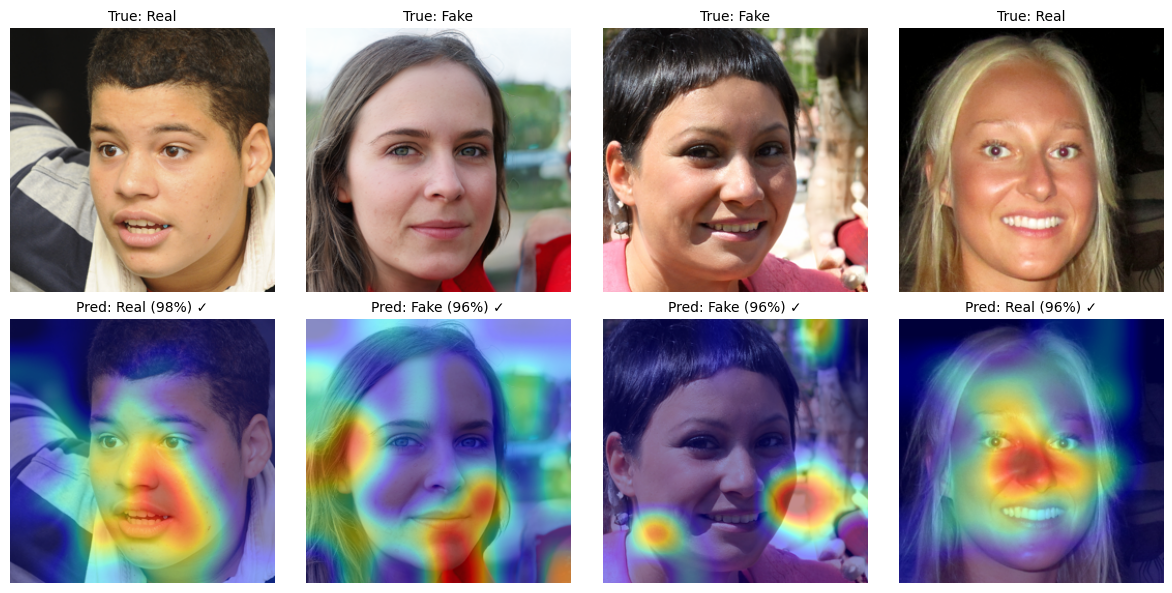

Saved: /kaggle/working/gradcam_results/publication/gradcam_grid_4col.png
Saved: /kaggle/working/gradcam_results/publication/gradcam_grid_4col.pdf


In [7]:
# Cell 7: Run Pipeline & Build a Single 2-Row x 4-Column Publication Figure

SAVE_DIR = "/kaggle/working/gradcam_results/publication"
os.makedirs(SAVE_DIR, exist_ok=True)
all_results = []

for i, img_path in enumerate(sample_images):
    device = DEVICES[i % len(DEVICES)]
    true_label = infer_true_label(img_path)
    with tf.device(device):
        original_img_array, img_batch = load_and_preprocess_image(img_path)
        heatmap, predictions = make_gradcam_heatmap(img_batch, model, last_conv_layer_name)
        prob = float(predictions[0][0])
        pred_label = CLASS_NAMES[1] if prob >= 0.5 else CLASS_NAMES[0]
        confidence = prob if prob >= 0.5 else 1 - prob
        overlay = overlay_heatmap_smooth(original_img_array, heatmap)
        all_results.append({"path": img_path, "true": true_label, "pred": pred_label,
                             "conf": confidence, "orig": original_img_array.astype("uint8"), "overlay": overlay})
        print(f"[{device}] {os.path.basename(img_path)} | True: {true_label} -> Pred: {pred_label} ({confidence:.1%})")

# Build one combined figure: row 1 = originals, row 2 = Grad-CAM overlays
n = len(all_results)
fig, axes = plt.subplots(2, n, figsize=(3 * n, 6))

for col, res in enumerate(all_results):
    correct = "✓" if res["true"] == res["pred"] else "✗"
    axes[0, col].imshow(res["orig"])
    axes[0, col].set_title(f"True: {res['true']}", fontsize=10)
    axes[0, col].axis("off")

    axes[1, col].imshow(res["overlay"])
    axes[1, col].set_title(f"Pred: {res['pred']} ({res['conf']:.0%}) {correct}", fontsize=10)
    axes[1, col].axis("off")

plt.tight_layout()
grid_png = os.path.join(SAVE_DIR, "gradcam_grid_4col.png")
grid_pdf = os.path.join(SAVE_DIR, "gradcam_grid_4col.pdf")
plt.savefig(grid_png, dpi=300, bbox_inches="tight")
plt.savefig(grid_pdf, bbox_inches="tight")
plt.show()

print("Saved:", grid_png)
print("Saved:", grid_pdf)

/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 256, 256, 3))
  warnings.warn(msg)


Saved: /kaggle/working/gradcam_results/publication/demo_Real_real_6302.png


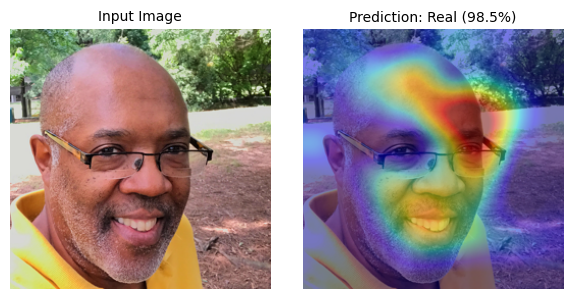

{'image_path': '/kaggle/input/datasets/troykueh/real-vs-fake-faces-stylegan3/Real faces/real_6302.png',
 'predicted_label': 'Real',
 'confidence': 0.9850183129310608}

In [8]:
def predict_and_explain(image_path, save=True):
    """Single entry point: takes any face image, returns prediction + Grad-CAM explanation."""
    original_img_array, img_batch = load_and_preprocess_image(image_path)
    heatmap, predictions = make_gradcam_heatmap(img_batch, model, last_conv_layer_name)
    prob = float(predictions[0][0])
    pred_label = CLASS_NAMES[1] if prob >= 0.5 else CLASS_NAMES[0]
    confidence = prob if prob >= 0.5 else 1 - prob
    overlay = overlay_heatmap_smooth(original_img_array, heatmap)

    fig, axes = plt.subplots(1, 2, figsize=(6, 3))
    axes[0].imshow(original_img_array.astype("uint8")); axes[0].set_title("Input Image", fontsize=10); axes[0].axis("off")
    axes[1].imshow(overlay); axes[1].set_title(f"Prediction: {pred_label} ({confidence:.1%})", fontsize=10); axes[1].axis("off")
    plt.tight_layout()

    if save:
        fname = os.path.splitext(os.path.basename(image_path))[0]
        out_path = os.path.join(SAVE_DIR, f"demo_{pred_label}_{fname}.png")
        plt.savefig(out_path, dpi=300, bbox_inches="tight")
        print("Saved:", out_path)

    plt.show()
    return {"image_path": image_path, "predicted_label": pred_label, "confidence": confidence}

# Example — swap in any image path to test
predict_and_explain(random.choice(all_images))

In [9]:
# Cell 9: Interactive Upload — Predict + Grad-CAM on Any Image

import ipywidgets as widgets
from IPython.display import display, clear_output

upload_widget = widgets.FileUpload(accept='image/*', multiple=False, description='Upload Image')
output_area = widgets.Output()

def on_upload_change(change):
    with output_area:
        clear_output()
        if not upload_widget.value:
            return

        uploaded = upload_widget.value
        # ipywidgets versions differ: older returns a dict, newer returns a tuple
        if isinstance(uploaded, dict):
            file_info = list(uploaded.values())[0]
            content, filename = file_info['content'], file_info['metadata']['name']
        else:
            file_info = uploaded[0]
            content, filename = file_info['content'], file_info['name']

        temp_path = f"/kaggle/working/{filename}"
        with open(temp_path, 'wb') as f:
            f.write(content)

        print(f"Uploaded: {filename}\n")
        result = predict_and_explain(temp_path, save=True)
        print(result)

upload_widget.observe(on_upload_change, names='value')

display(widgets.VBox([
    widgets.HTML("<b>Upload a face image to get a live prediction + Grad-CAM explanation:</b>"),
    upload_widget,
    output_area
]))